# 2. Does the task context change how the NM couples to movement?

If an NM tracks movement as such, its coupling to movement should be the same everywhere. If it tracks movement *in a context*, the coupling should change with what the task has just done or is about to do. That is a "beyond task" result that a task-only or additive task + motor model cannot show.

Per trial and epoch: the mean NM signal and the mean vigor (paw speed, wheel speed, whisker ME, lick rate; session z-scored). Epochs:
- **pre-Q**: the 0.3–0.6 s before the final quiescence;
- **Q**: the final quiescence, wheel held still;
- **post-stim**: 0–0.5 s after stimulus onset;
- **post-fb**: 0–1 s after feedback.

Contexts:
- **prev outcome**: last trial rewarded vs error;
- **late session**: second half of the session;
- **outcome**: this trial rewarded vs error (post-fb only).

Per fiber, epoch and context, one OLS fit: NM ~ task + context + Σ β·vigor + Σ γ·vigor × context. γ is the change in coupling in that context. The interactions' cross-validated ΔR² is tested against the context labels rotated over trials. Vigor is z-scored over the whole session, so a context with less movement keeps its narrower range. The range check below flags cells where that could fake a coupling change. Mice are the unit. Functions and cache: `context_coupling.py`.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators' / 'behavioural_states'))
import context_coupling as cc
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)

if not (cc.OUT / f'context_coupling_{cc.ns.RUN}.pkl').exists():
    cc.run()
D = cc.load()
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
CELLS = [(c, e) for c, eps in cc.CONTEXTS.items() for e in eps]
VIG = cc.ns.VIGOR
D.groupby('target_NM').agg(mice=('subject', 'nunique'), fibers=('eid', 'nunique')).loc[NM_ORDER]

,mice,fibers
target_NM,,
DR-5HT,9,140
VTA-DA,7,140
SNc-DA,6,65
LC-NE,8,96
NBM-ACh,7,50


## Does the context change the coupling at all?

Excess cross-validated ΔR² of the vigor × context interactions (beyond the additive model, minus the rotated-context null), mouse means. Stars: across-mice t-test, * p < 0.05, ** p < 0.01.

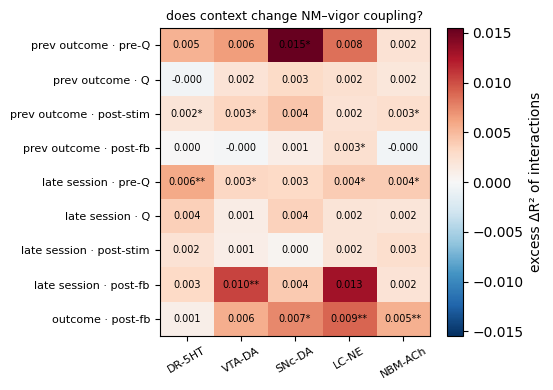

In [2]:
res, _ = cc.across_mice(D, 'excess')
res['cell'] = list(zip(res['context'], res['epoch']))
M = res.pivot_table(index='cell', columns='target_NM', values='mean').reindex(index=CELLS, columns=NM_ORDER)
P = res.pivot_table(index='cell', columns='target_NM', values='p').reindex(index=CELLS, columns=NM_ORDER)
fig, ax = plt.subplots(figsize=(5.5, 4))
lim = np.nanmax(np.abs(M.values))
im = ax.imshow(M.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        p = P.values[i, j]
        ax.text(j, i, f'{M.values[i, j]:.3f}' + ('**' if p < 0.01 else '*' if p < 0.05 else ''), ha='center', va='center', fontsize=7)
ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, rotation=30, fontsize=8)
ax.set_yticks(range(len(CELLS)), [f'{c} · {e}' for c, e in CELLS], fontsize=8)
fig.colorbar(im, ax=ax, label='excess ΔR² of interactions')
ax.set_title('does context change NM–vigor coupling?', fontsize=9)
fig.tight_layout()

## Which coupling changes, and how?

γ (change in standardised coupling in the context) per vigor signal, mouse means. Only cells with p < 0.05 across mice are printed in the table. The figure shows the coupling in each context (β for c = 0, β + γ for c = 1) for every NM and vigor signal.

,context,epoch,target_NM,vigor,mice,mean,sem,positive,p
0,late session,Q,DR-5HT,whisker ME,9,-0.034,0.014,2/9,0.045
4,late session,Q,VTA-DA,whisker ME,7,-0.052,0.016,0/7,0.019
4,late session,post-fb,LC-NE,lick rate,8,-0.034,0.010,1/8,0.009
7,late session,post-fb,NBM-ACh,whisker ME,7,-0.046,0.015,1/7,0.022
8,late session,post-fb,SNc-DA,whisker ME,6,-0.070,0.020,0/6,0.016
7,late session,post-fb,VTA-DA,lick rate,7,-0.051,0.014,0/7,0.011
9,late session,post-fb,VTA-DA,whisker ME,7,-0.188,0.034,0/7,0.001
12,late session,post-stim,NBM-ACh,whisker ME,7,-0.059,0.019,1/7,0.021
14,late session,post-stim,VTA-DA,paw speed,7,0.073,0.021,6/7,0.012
15,late session,pre-Q,DR-5HT,whisker ME,9,-0.046,0.013,1/9,0.007


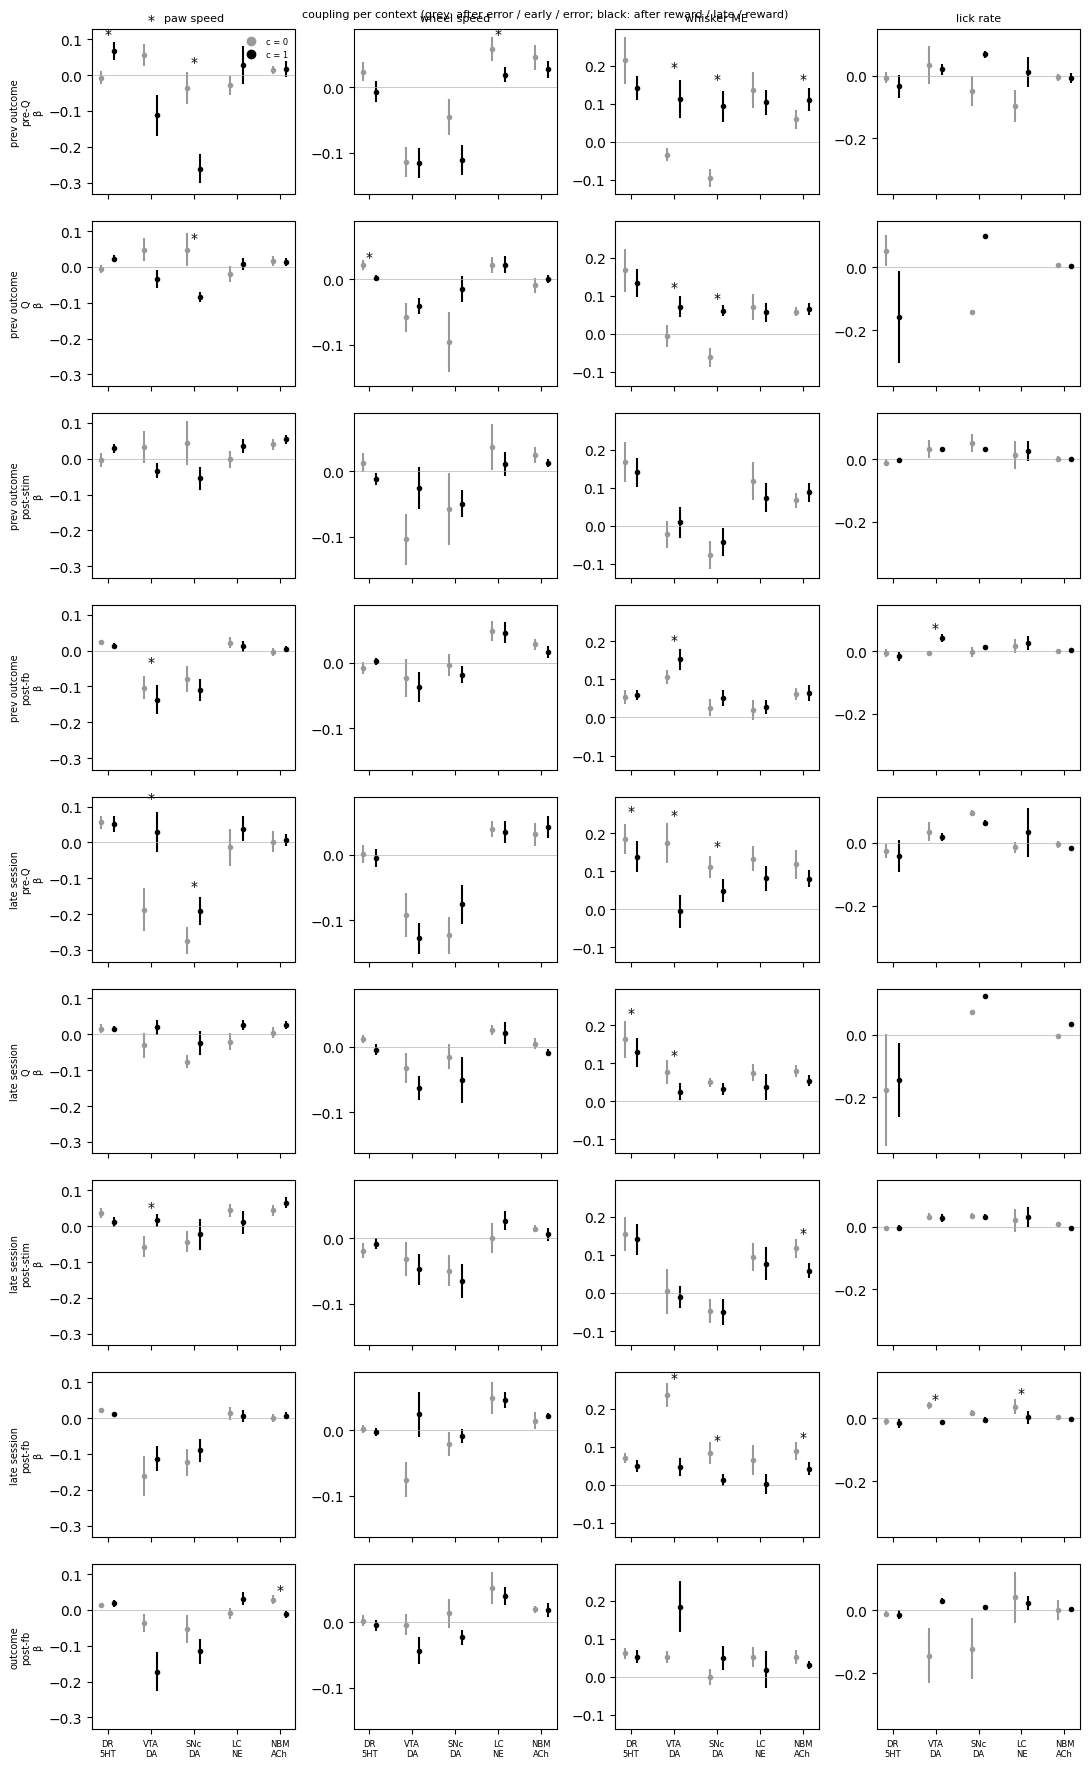

In [3]:
rows = []
for v in VIG:
    r, _ = cc.across_mice(D, f'gamma {v}')
    rows.append(r.assign(vigor=v))
G = pd.concat(rows)
sig = G[G['p'] < 0.05].sort_values(['context', 'epoch', 'target_NM', 'vigor'])
display(sig[['context', 'epoch', 'target_NM', 'vigor', 'mice', 'mean', 'sem', 'positive', 'p']].round(3))

LEVELS = {'prev outcome': ('after error', 'after reward'), 'late session': ('early', 'late'), 'outcome': ('error', 'reward')}
fig, axes = plt.subplots(len(CELLS), len(VIG), figsize=(11, 2.0 * len(CELLS)), sharey='col')
for i, (c, e) in enumerate(CELLS):
    d = D[(D['context'] == c) & (D['epoch'] == e)]
    for j, v in enumerate(VIG):
        ax = axes[i, j]
        m = d.groupby(['target_NM', 'subject'])[[f'beta {v}', f'gamma {v}']].mean()
        b0, b1 = m[f'beta {v}'], m[f'beta {v}'] + m[f'gamma {v}']
        for k, nm in enumerate(NM_ORDER):
            if nm not in b0.index.get_level_values(0):
                continue
            x0, x1 = b0.loc[nm], b1.loc[nm]
            ax.errorbar(k - 0.15, x0.mean(), x0.sem(), fmt='o', ms=3, color='0.6')
            ax.errorbar(k + 0.15, x1.mean(), x1.sem(), fmt='o', ms=3, color='k')
            p = G[(G['context'] == c) & (G['epoch'] == e) & (G['target_NM'] == nm) & (G['vigor'] == v)]['p']
            if len(p) and p.iat[0] < 0.05:
                ax.text(k, max(x0.mean(), x1.mean()) + 1.5 * x1.sem(), '*', ha='center')
        ax.axhline(0, c='0.7', lw=0.5)
        ax.set_xticks(range(len(NM_ORDER)), [n.split('-')[0] + '\n' + n.split('-')[1] for n in NM_ORDER] if i == len(CELLS) - 1 else [], fontsize=6)
        if i == 0: ax.set_title(v, fontsize=8)
        if j == 0: ax.set_ylabel(f'{c}\n{e}\nβ', fontsize=7)
axes[0, 0].plot([], [], 'o', color='0.6', label='c = 0'); axes[0, 0].plot([], [], 'o', color='k', label='c = 1')
axes[0, 0].legend(fontsize=6, frameon=False)
fig.suptitle('coupling per context (grey: after error / early / error; black: after reward / late / reward)', fontsize=8)
fig.tight_layout()

## Range check

Interactions can be faked when a context restricts the range of a vigor signal (e.g. little licking after errors). Per cell, the SD of each vigor signal in c = 1 relative to c = 0 (mean over fibers). Cells with a ratio outside 0.67–1.5 should be read with care.

In [4]:
rng_tab = []
for c, e in CELLS:
    d = D[(D['context'] == c) & (D['epoch'] == e)]
    rng_tab.append({'cell': f'{c} · {e}', **{v: (d[f'sd {v} | c=1'] / d[f'sd {v} | c=0']).median() for v in VIG}})
R = pd.DataFrame(rng_tab).set_index('cell')
display(R.round(2).style.apply(lambda col: ['background-color: #fdd' if (x < 0.67 or x > 1.5) else '' for x in col]))

,paw speed,wheel speed,whisker ME,lick rate
cell,,,,
prev outcome · pre-Q,0.740000,0.920000,0.730000,1.530000
prev outcome · Q,0.840000,1.050000,0.970000,2.380000
prev outcome · post-stim,0.950000,1.010000,0.960000,1.230000
prev outcome · post-fb,0.890000,0.920000,0.860000,1.060000
late session · pre-Q,1.080000,0.990000,1.120000,0.960000
late session · Q,1.070000,0.960000,1.090000,0.880000
late session · post-stim,1.080000,1.010000,1.110000,0.900000
late session · post-fb,1.060000,1.100000,1.010000,0.900000
outcome · post-fb,0.560000,0.760000,0.340000,3.380000


## Reading

Context changes the coupling only a little overall: interaction ΔR² 0.002–0.015 beyond the additive model. But two patterns are consistent across mice.

**1. After a reward, DA's coupling to movement before the next stimulus reorganises.**
- In pre-Q and Q, the change in coupling (γ) is:
  - whisking: + (SNc 6/6, VTA 6–7/7);
  - paw: − (SNc 0/6, VTA 0/7 positive);
  - pre-Q SNc: interaction ΔR² p = 0.01.
- After an error, DA is weakly anti-coupled to whisking (β ≈ −0.09). After a reward, the coupling flips to positive and DA becomes clearly lower when the paw moves.
- A sign flip can't come from a narrower movement range.
- 5HT shows the same kind of change for the paw: coupling rises after reward, 9/9 mice.
- **Caveat:** after a reward, pre-Q partly overlaps the end of reward consumption. Licking is 1.5× more variable there, and whisking and paw co-occur with licking bouts. Licking is in the model, but this needs a dedicated check.

**2. Late in the session, coupling to whisking weakens** in DA, 5HT and ACh, across epochs. Strongest is VTA after feedback (γ −0.19, 0/7 positive). The movement ranges are unchanged (SD ratios ≈ 1). **Caveat:** DA loses gain over the session (notebook 7, section 5), which would scale every coupling down. This has to be compared with how much the task responses shrink before it can be read as a change in coupling.

**Not interpretable:** *outcome · post-fb*. After errors there is almost no licking and much less whisking and paw movement (SD ratios 0.34–3.4), so the interactions there are mostly range effects.

**Checks to do next:**
1. **Gain control** for the late-session effect: change in coupling relative to the change in the stimulus/feedback response of the same fiber.
2. **Reward-consumption control** for the previous-outcome effect: only trials with no licking in pre-Q, or only pre-Q periods inside the trial (after resets) rather than at the end of the ITI.
3. Time-resolved coupling within the epoch.